# Unsupervised AD with DBSCAN clustering

# Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler,RobustScaler

# Download data
using a url to a shared google drive

In [ ]:
import pandas as pd
option=2
if option==1:
  # URL to the CSV file (the URL you shared with the students)
  url = "https://drive.google.com/uc?export=download&id=1-6nz0ldZcD6zflGE2QnExvfoMYaioOH4"
elif option==2:
  # URL to the CSV file (the URL you shared with the students)
  #url = "https://drive.google.com/uc?export=download&id=1HTGbKEfArSCAwD9UN7yMb2SYnhhMcu_c"
  url = "https://drive.google.com/uc?export=download&id=1lo7kzz6nGQYiM18dnN5dodgMUDmjym_g"


# Load the CSV into a DataFrame directly from the URL
df = pd.read_csv(url)

# Display the first few rows to confirm
df.head()

,temperature,vibrations,state,label
0,65.908897,5.092387,2.0,0.0
1,36.991467,10.778417,1.0,0.0
2,33.815246,6.019315,1.0,0.0
3,41.070469,6.131392,1.0,0.0
4,70.379023,2.322838,2.0,0.0


# Visualize the data

Text(0, 0.5, 'Vibrations')

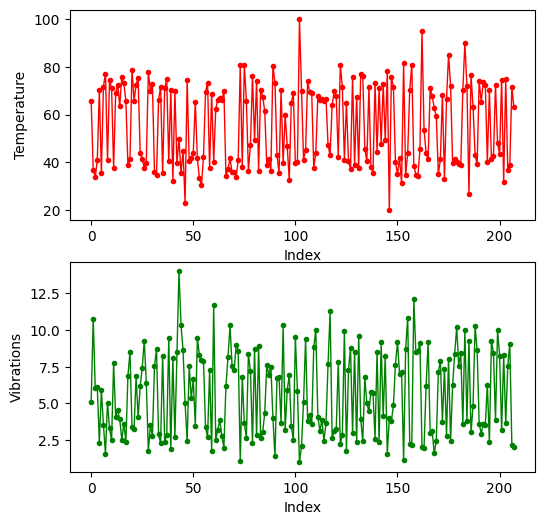

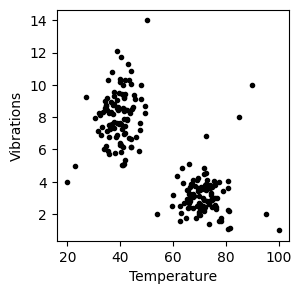

In [ ]:
# time series plots
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].plot(df['temperature'],'o-r',ms=3,lw=1)
axes[0].set_xlabel("Index")
axes[0].set_ylabel("Temperature")

axes[1].plot(df['vibrations'],'o-g',ms=3,lw=1)
axes[1].set_xlabel("Index")
axes[1].set_ylabel("Vibrations")

# scatter plot
plt.figure(figsize=(3,3))
plt.plot(df['temperature'],df['vibrations'],'ok',ms=3)
plt.xlabel('Temperature')
plt.ylabel('Vibrations')

# AD with DBSCAN

## extract only the variables from the dataframe

In [ ]:
data = df[['temperature','vibrations']].copy().values

## DBSCAN prediction

In [ ]:
# Scale the data - important for better detection
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)  # eps and min_samples are hyperparameters
dbscan_pred = dbscan.fit_predict(data_scaled)



## plot results

### plot DBSCAN prediction


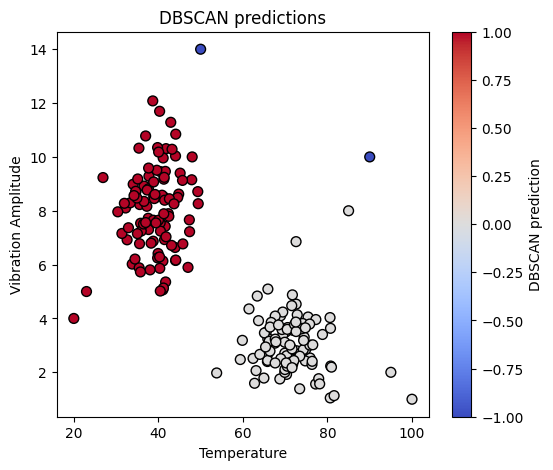

In [ ]:
# Plot the scatter of the data with DBSCAN predictions as the point color
fig, axes = plt.subplots(1, 1, figsize=(6, 5))
scatter_dbscan_scores = axes.scatter(
    data[:, 0], data[:, 1],
    c=dbscan_pred, cmap='coolwarm', edgecolor='k', s=50
)
axes.set_title("DBSCAN predictions")
axes.set_xlabel("Temperature")
axes.set_ylabel("Vibration Amplitude")
fig.colorbar(scatter_dbscan_scores, ax=axes, label='DBSCAN prediction')

 ## Think
  1. what determines the detection outcome here?
  2. How could you change it?
  3. What is the problematic?





# Determine hyperparameters
1. Start with MinPts = 2*dim = 4
2. Look for a knee in the distance to the k-NN with k=MinPts.

In [ ]:

from sklearn.neighbors import NearestNeighbors

def calculate_k_distance(data, k):
    # Fit the NearestNeighbors model
    nbrs = NearestNeighbors(n_neighbors=k+1).fit(data)

    # Find the k-neighbors for each point
    distances, indices = nbrs.kneighbors(data)

    # Exclude the distance to itself (first column)
    k_distances = distances[:, k]

    # Calculate the median of the k-distances for each point
    median_distances = np.median(k_distances)

    # Calculate the overall median of these median distances
    overall_median = np.median(median_distances)

    return k_distances

# set the MinPts to 2*dim = 2*2 in our case.
MinPts_est = 4
k = MinPts_est
# calculate for each point, the distance to its kth neareast neighbour
k_distances = calculate_k_distance(data_scaled, k)


How to calculate the knee? look at the sorted k_distances array and find the point at which there is a sudden jump.

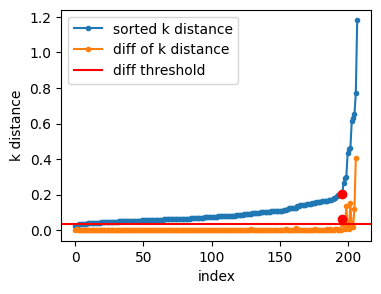

In [ ]:
# sort the k_distances
k_nn_sorted = np.sort(k_distances)
# take the diff of the sorted array
k_nn_diff = np.diff(k_nn_sorted)
# for each point decide if it deviates by much from the distirbution of the points before it
d_from_q90 = []
for i,k in enumerate(k_nn_diff):
  if i>1: # otherwise no comparison to previous points possible
    subset  = k_nn_diff[:(i-1)]
    iqr = np.quantile(subset,0.9) - np.quantile(subset,0.1)
    thresh = np.median(subset) + 10*iqr
    d_from_q90.append(k-thresh)
# find the first time we cross the threshold
i_knee = np.min(np.where(np.array(d_from_q90[1:])>0))+1

# we dropped i=0 and i=1, now add them back
i_knee_knn = i_knee+2

# plot the sorted k distance and its diff
plt.figure(figsize=(4,3))
plt.plot(k_nn_sorted,'.-',label='sorted k distance')
plt.plot(i_knee_knn,k_nn_sorted[i_knee_knn],'or')
plt.plot(k_nn_diff,'.-',label='diff of k distance')
plt.plot(i_knee_knn,k_nn_diff[i_knee_knn],'or')
plt.axhline(thresh,color='r',label='diff threshold')
plt.xlabel('index')
plt.ylabel('k distance')
plt.legend()

eps_est = k_nn_sorted[i_knee_knn]


## Repeat DBSCAN with estimated parameters

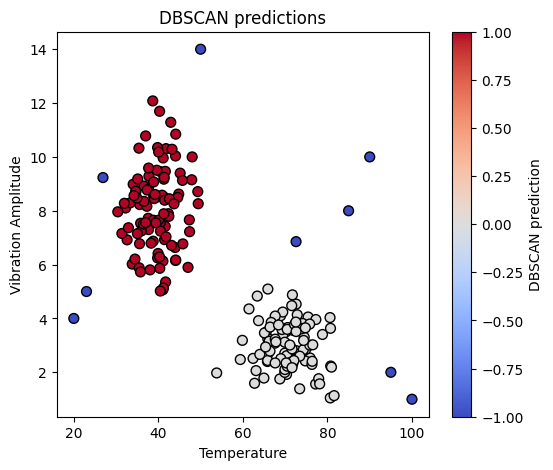

In [ ]:
# Scale the data (as before)
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# Apply DBSCAN with the parameters we estimated
dbscan = DBSCAN(eps=eps_est, min_samples=MinPts_est)
dbscan_pred = dbscan.fit_predict(data_scaled)

# Plot the scatter of the data with DBSCAN scores as their color
fig, axes = plt.subplots(1, 1, figsize=(6, 5))
scatter_dbscan_scores = axes.scatter(
    data[:, 0], data[:, 1],
    c=dbscan_pred, cmap='coolwarm', edgecolor='k', s=50
)
axes.set_title("DBSCAN predictions")
axes.set_xlabel("Temperature")
axes.set_ylabel("Vibration Amplitude")
fig.colorbar(scatter_dbscan_scores, ax=axes, label='DBSCAN prediction')

## Think
1. Did we really need the clustering for outlier detection? Hint: how did we determine epsilon?
2. How sensitive is the result to the two hyperparameters. Can you suggest an analysis and visualize it?